# 02 · 物理资产构建

真实重建几何 → VLM 物性先验 → 视频约束 → 碰撞与仿真检查 → USD 导出。


In [1]:
import json
import uuid

from examples._display import setup_notebook, show_animation, show_image, show_metrics

PROJECT_ROOT, OUTPUT_DIR = setup_notebook("physical_asset_building")

from physrealx import ArtifactRef, AssetSpec, PhysRealX
from physrealx.integrations.physical_estimation import inspect_video

px = PhysRealX.open(PROJECT_ROOT / ".physrealx")
run_key = uuid.uuid4().hex[:12]


Python,3.11.15
解释器,/home/yxp/miniconda3/envs/PhysReal-X/bin/python


## 1. 资产与视频

In [2]:
upstream = json.loads(
    (PROJECT_ROOT / "examples/real_assets_and_digital_twin/output/results.json").read_text()
)
reference_model = ArtifactRef.model_validate(upstream["reference-model.json"])
reconstruction_report = ArtifactRef.model_validate(upstream["reconstruction-report.json"])
registration = ArtifactRef.model_validate(upstream["reference-registration.json"])
reference = json.loads(px.artifacts.get_bytes(reference_model))

saved_prior_path = OUTPUT_DIR / "vlm-physics-prior.json"
reconstructed_geometry = None
if saved_prior_path.exists():
    try:
        cached_prior = json.loads(saved_prior_path.read_text())
        candidate = ArtifactRef.model_validate(cached_prior["source_geometry"])
        cached_geometry = json.loads(px.artifacts.get_bytes(candidate)) if px.artifacts.verify(candidate) else {}
        if (
            cached_geometry.get("source_reconstruction") == reconstruction_report.model_dump(mode="json")
            and cached_geometry.get("source_registration") == registration.model_dump(mode="json")
            and cached_geometry.get("source_reference") == reference_model.model_dump(mode="json")
        ):
            reconstructed_geometry = candidate
    except (OSError, ValueError, KeyError):
        pass
if reconstructed_geometry is None:
    reconstructed_geometry = px.assets.register_reconstruction_geometry(
        reconstruction_report, registration
    )
real_geometry = json.loads(px.artifacts.get_bytes(reconstructed_geometry))
video_dir = (
    PROJECT_ROOT / "examples/real_assets_and_digital_twin/input/ArtModeling/laptop1/real/video"
)
readiness = inspect_video(px.artifacts, video_dir)
video_status = json.loads(px.artifacts.get_bytes(readiness))
show_metrics({**video_status["counts"], "几何来源": real_geometry["geometry_source"]})


depth,186
img,186
link_mask,186
mask,186
几何来源,real_artgs_reconstruction


## 2. VLM 物性先验

方法：VLM（Qwen3-VL）。


In [3]:
images = tuple(
    px.artifacts.put_file(video_dir / "img" / f"{index}.png", media_type="image/png")
    for index in (0, 46, 93, 139, 185)
)
saved_prior = saved_prior_path
prior = None
if saved_prior.exists():
    saved = json.loads(saved_prior.read_text())
    if (
        saved["source_reference"] == reference_model.model_dump(mode="json")
        and saved["registration"] == registration.model_dump(mode="json")
        and saved["source_geometry"] == reconstructed_geometry.model_dump(mode="json")
        and len(saved["images"]) == len(images)
        and all(
            px.artifacts.get_bytes(ArtifactRef.model_validate(old)) == px.artifacts.get_bytes(new)
            for old, new in zip(saved["images"], images)
        )
    ):
        prior = px.artifacts.put_json(saved)
if prior is None:
    prior = px.assets.predict_physics(
        reference_model,
        registration,
        reconstructed_geometry,
        images,
        python="/home/yxp/miniconda3/envs/qwen/bin/python",
        model="/mnt/53dad72e-a787-4c09-961e-eff73e08888e/yxp/Desktop/ArtCot/models/Qwen3-VL-8B-Instruct",
        revision="local-content-hashed",
    )
prediction = json.loads(px.artifacts.get_bytes(prior))
show_metrics(
    {
        name + " mass (kg)": (
            f"{body['mass_kg']['value']} [{body['mass_kg']['lower']}, {body['mass_kg']['upper']}]"
        )
        for name, body in prediction["prediction"]["bodies"].items()
    }
)


body mass (kg),"1.2 [0.8, 1.6]"
cover mass (kg),"0.3 [0.2, 0.4]"


## 3. 视频约束

可视化 RGB、深度、物体 Mask 与部件 Mask。


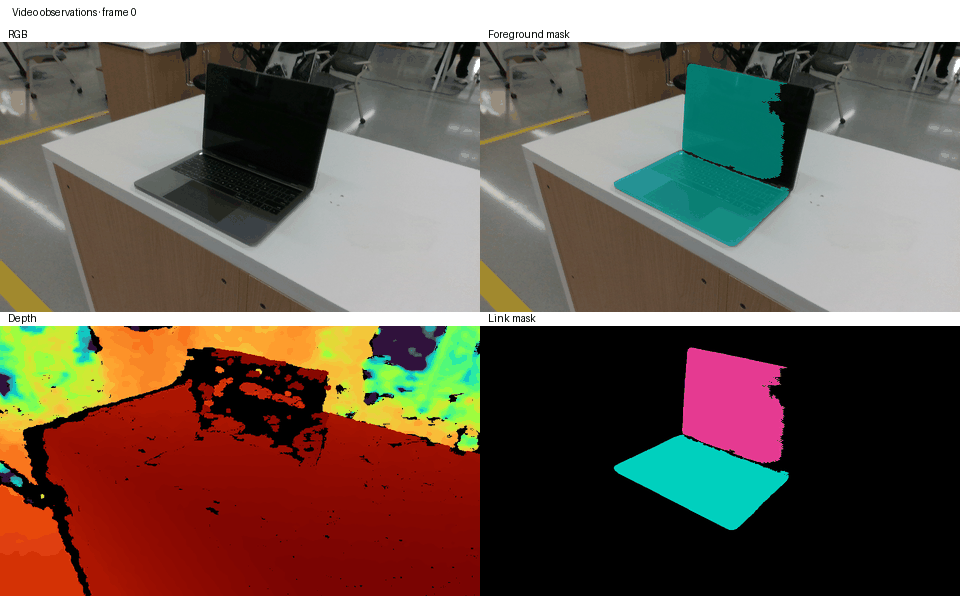

视频观测,RGB / Depth / Mask 已齐备
几何修正,待相机位姿


In [4]:
video_preview = px.assets.preview_physics_video(video_dir)
show_animation(px.artifacts.get_bytes(video_preview))
geometry_refinement = None
evidence_path = PROJECT_ROOT / "examples/physical_asset_building/input/video-geometry-evidence.json"
if evidence_path.exists():
    evidence = px.artifacts.put_json(json.loads(evidence_path.read_text()))
    geometry_refinement = px.assets.refine_video_geometry(evidence)
    refinement = json.loads(px.artifacts.get_bytes(geometry_refinement))
    if refinement["source_geometry"] != reconstructed_geometry.model_dump(mode="json"):
        raise ValueError("视频证据与当前重建资产不一致")
    geometry_refs = refinement["geometries"]
    show_metrics({name: value["status"] for name, value in refinement["links"].items()})
else:
    geometry_refs = real_geometry["geometries"]
    show_metrics({"视频观测": "RGB / Depth / Mask 已齐备", "几何修正": "待相机位姿"})


## 4. 碰撞体与装配

In [5]:
collision_reports = []
for link in reference["links"]:
    operation = px.assets.build_collision(
        ArtifactRef.model_validate(geometry_refs[link["name"]]),
        method="coacd",
        config={
            "source_unit": "m",
            "link": link["name"],
            "threshold_m": 0.008,
            "max_parts": 48,
            "max_volume_error": 0.15,
            "preprocessing": "coacd",
            "weld_tolerance_m": 0.000001,
        },
    )
    collision_reports.append(operation.output("collision_build_report"))
assembly_input = px.artifacts.put_json(
    {
        "schema": "physrealx.reference-assembly-input/1",
        "resource_id": f"laptop1.physical.{run_key}",
        "version": "1.0.0",
        "display_name": "Laptop reconstructed physical asset",
        "reference_model": reference_model.model_dump(mode="json"),
        "reconstructed_geometry": reconstructed_geometry.model_dump(mode="json"),
        "registration": registration.model_dump(mode="json"),
        "predicted_physics": prior.model_dump(mode="json"),
        "geometry_refinement": geometry_refinement.model_dump(mode="json")
        if geometry_refinement
        else None,
        "collision_reports": [ref.model_dump(mode="json") for ref in collision_reports],
    }
)
assembly = px.assets.assemble(assembly_input, method="reference_asset_assembly").output(
    "asset_assembly"
)
asset = AssetSpec.model_validate(json.loads(px.artifacts.get_bytes(assembly))["asset_spec"])


## 5. 碰撞修正与仿真检查

初始穿透 (mm),14.3
仿真可行性,PASSED
最终穿透 (mm),0
铰链局部代理剔除,14.6%


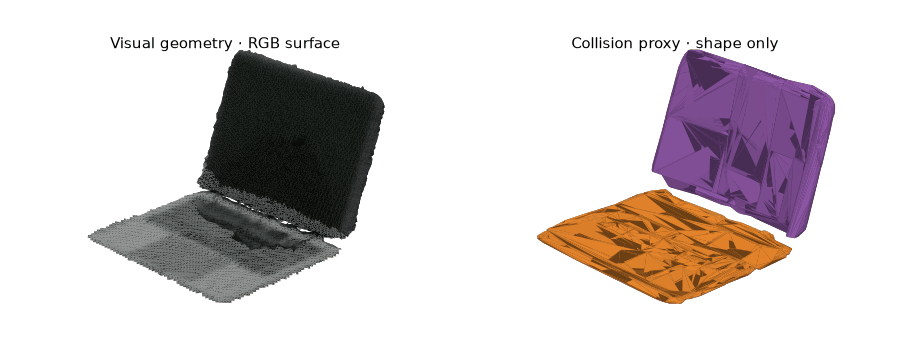

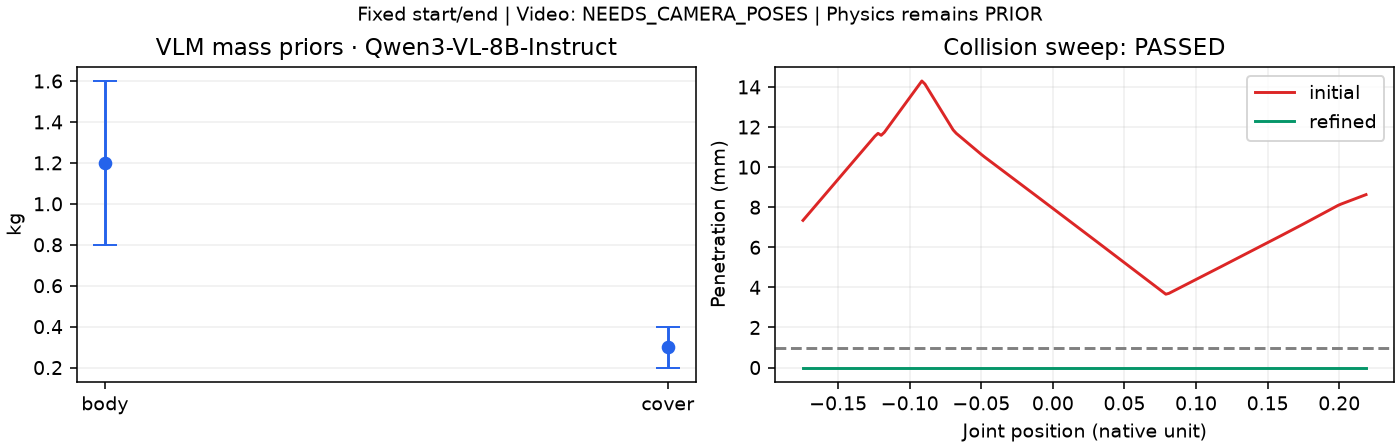

In [6]:
initial_assembly = assembly
initial_feasibility = px.assets.check_physics_feasibility(initial_assembly)
initial_check = json.loads(px.artifacts.get_bytes(initial_feasibility))
collision_refinement = None
if initial_check["status"] == "FAILED":
    collision_refinement = px.assets.optimize_articulated_collision(
        initial_assembly, initial_feasibility
    )
    refinement = json.loads(px.artifacts.get_bytes(collision_refinement))
    if refinement["status"] == "PASSED":
        candidate_input = ArtifactRef.model_validate(refinement["candidate_assembly_input"])
        assembly = px.assets.assemble(
            candidate_input, method="reference_asset_assembly"
        ).output("asset_assembly")
        asset = AssetSpec.model_validate(
            json.loads(px.artifacts.get_bytes(assembly))["asset_spec"]
        )
feasibility = px.assets.check_physics_feasibility(assembly)
check = json.loads(px.artifacts.get_bytes(feasibility))
metrics = {
    "初始穿透 (mm)": 1000 * initial_check["max_penetration_m"],
    "仿真可行性": check["status"],
    "最终穿透 (mm)": 1000 * check["max_penetration_m"],
}
if collision_refinement is not None:
    metrics["铰链局部代理剔除"] = f"{100 * refinement['removed_volume_fraction']:.1f}%"
show_metrics(metrics)
physical_preview = px.assets.preview_physical_asset(assembly)
report_preview = px.assets.preview_physics_report(
    prior, feasibility, readiness, initial_feasibility
)
show_animation(px.artifacts.get_bytes(physical_preview))
show_image(px.artifacts.get_bytes(report_preview))

## 6. 导出

In [7]:
package = px.assets.package(assembly, method="openusd")
usd = package.output("usd_asset_bundle")
package_manifest = package.output("asset_package_manifest")
asset_ref = None
if check["status"] == "PASSED":
    quality = px.assets.validate(asset, profile="simulation")
    assert quality.passed, quality.model_dump(mode="json")
    asset_ref = px.assets.register(asset)
results = {
    "asset": asset_ref.model_dump(mode="json") if asset_ref else None,
    "source_reference": reference_model.model_dump(mode="json"),
    "source_reconstruction": reconstruction_report.model_dump(mode="json"),
    "reconstructed_geometry": reconstructed_geometry.model_dump(mode="json"),
    "prior": prior.model_dump(mode="json"),
    "readiness": readiness.model_dump(mode="json"),
    "initial_assembly": initial_assembly.model_dump(mode="json"),
    "initial_feasibility": initial_feasibility.model_dump(mode="json"),
    "collision_refinement": collision_refinement.model_dump(mode="json")
    if collision_refinement
    else None,
    "assembly": assembly.model_dump(mode="json"),
    "package": package_manifest.model_dump(mode="json"),
    "usd": usd.model_dump(mode="json"),
    "video_preview": video_preview.model_dump(mode="json"),
    "preview": physical_preview.model_dump(mode="json"),
    "feasibility": feasibility.model_dump(mode="json"),
    "workflow_status": "VIDEO_REFINEMENT_REPORTED"
    if geometry_refinement
    else "NEEDS_CAMERA_POSES",
    "independent_physical_validation": False,
}
exports = {
    "registered-reconstruction-geometry.json": reconstructed_geometry,
    "vlm-physics-prior.json": prior,
    "video-readiness.json": readiness,
    "video-mask-manifest.json": ArtifactRef.model_validate(video_status["mask_manifest"]),
    "video-observations.gif": video_preview,
    "initial-assembly.json": initial_assembly,
    "initial-feasibility.json": initial_feasibility,
    "assembly.json": assembly,
    "package.json": package_manifest,
    "physical-asset.usdz": usd,
    "feasibility.json": feasibility,
    "physical-asset-preview.gif": physical_preview,
    "physics-report.png": report_preview,
}
if collision_refinement is not None:
    exports["collision-refinement.json"] = collision_refinement
if geometry_refinement is not None:
    exports["geometry-refinement.json"] = geometry_refinement
px.artifacts.export(OUTPUT_DIR, results, files=exports)
print(OUTPUT_DIR / "results.json")

/mnt/53dad72e-a787-4c09-961e-eff73e08888e/yxp/Desktop/pingtaidajian/PhysReal-X/examples/physical_asset_building/output/results.json
